# Lab 01 – Sentiment Analysis Using Traditional Machine Learning

**Module:** PUSL3205 – Large Language Models and Generative AI

**Practical Topic:** Text Preprocessing, Bag-of-Words, TF-IDF and Machine Learning

**Programming Language:** Python

**Development Environment:** Google Colab

## 1. Introduction

Sentiment analysis is a Natural Language Processing (NLP) technique used to identify the emotional orientation of textual information, commonly as positive or negative.

This practical investigates sentiment classification using traditional machine learning approaches. It involves loading a labelled text dataset, preprocessing review sentences, exploring sentiment-related vocabulary, converting text into numerical features, training classification models and evaluating their predictive performance.

The UCI Sentiment Labelled Sentences dataset is used, containing reviews from Amazon, IMDb and Yelp.

## 2. Objectives

The objectives of this laboratory are to:

- Understand the fundamental NLP workflow for text classification.
- Load and explore a real-world labelled text dataset.
- Apply text preprocessing and cleaning techniques.
- Analyse positive and negative sentiment patterns.
- Convert text into Bag-of-Words representations.
- Explore TF-IDF as an additional feature representation.
- Train traditional machine learning classification models.
- Evaluate predictions using accuracy, precision, recall and F1-score.
- Test the trained classifier with previously unseen sentences.
- Identify common errors and limitations of traditional NLP techniques.

## 3. Tools and Technologies

The practical is implemented using Python in Google Colab.

The following libraries are used:

- **Pandas:** Loading, cleaning and analysing structured datasets.
- **NumPy:** Numerical processing and array operations.
- **NLTK:** Supporting natural language processing concepts.
- **Scikit-learn:** Text vectorisation, model training and evaluation.
- **Matplotlib:** Creating graphs and visualisations.
- **Seaborn:** Statistical visualisations.
- **Requests:** Downloading the dataset.
- **Joblib:** Saving and loading trained machine learning models.

These libraries provide the necessary functionality for developing and evaluating a traditional sentiment classification pipeline.

In [1]:
%pip install -q pandas numpy nltk scikit-learn matplotlib seaborn requests joblib


## 4. Environment Configuration

The required Python libraries are imported to support dataset processing, text preprocessing, exploratory data analysis, feature extraction, model training and evaluation.

A fixed random seed is used to improve reproducibility.

The project folders are created automatically to separate the dataset, notebook, experimental results, screenshots and saved model.

This structure helps maintain a clearly organised portfolio and simplifies the process of uploading the completed laboratory to GitHub.

In [2]:
import re
import html
import csv
import json
import joblib
import requests

from pathlib import Path
from io import BytesIO
from zipfile import ZipFile
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)

from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfVectorizer,
    ENGLISH_STOP_WORDS
)

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")

ROOT = Path("/content/Lab-01-Machine-Learning")

DATA_DIR = ROOT / "dataset"
RESULTS_DIR = ROOT / "results"
SCREENSHOTS_DIR = ROOT / "screenshots"
NOTEBOOKS_DIR = ROOT / "notebooks"
OUTPUT_DIR = ROOT / "output"

for folder in [
    ROOT,
    DATA_DIR,
    RESULTS_DIR,
    SCREENSHOTS_DIR,
    NOTEBOOKS_DIR,
    OUTPUT_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully.")
print("Project folders created successfully.")
print("Project location:", ROOT)

Libraries imported successfully.
Project folders created successfully.
Project location: /content/Lab-01-Machine-Learning


## 5. Dataset Collection and Loading

### 5.1 Dataset Description

The UCI Sentiment Labelled Sentences dataset is used for this experiment.

The dataset contains labelled customer and user reviews from three domains:

- Amazon – Product reviews.
- IMDb – Movie reviews.
- Yelp – Restaurant reviews.

Each sentence is associated with a binary sentiment label:

- **0:** Negative sentiment.
- **1:** Positive sentiment.

The three datasets are downloaded and combined into a single Pandas DataFrame.

A separate domain column is maintained to identify the original source of each review. This allows sentiment patterns to be compared across the different review categories.

**Dataset Source:** https://archive.ics.uci.edu/dataset/331/sentiment+labelled+sentences

In [3]:
DATASET_URL = (
    "https://archive.ics.uci.edu/static/public/331/"
    "sentiment+labelled+sentences.zip"
)

response = requests.get(DATASET_URL, timeout=60)
response.raise_for_status()

required_files = [
    "amazon_cells_labelled.txt",
    "imdb_labelled.txt",
    "yelp_labelled.txt"
]

dataframes = []

with ZipFile(BytesIO(response.content)) as archive:

    for filename in required_files:

        matching_files = [
            name for name in archive.namelist()
            if Path(name).name == filename
        ]

        if not matching_files:
            raise FileNotFoundError(
                f"Dataset file not found: {filename}"
            )

        file_content = archive.read(matching_files[0])

        (DATA_DIR / filename).write_bytes(file_content)

        temp_df = pd.read_csv(
            BytesIO(file_content),
            sep="\t",
            header=None,
            names=["review", "sentiment"],
            encoding="utf-8",
            quoting=csv.QUOTE_NONE
        )

        temp_df["domain"] = filename.replace(
            "_labelled.txt", ""
        )

        dataframes.append(temp_df)

        print(
            f"{filename}: {len(temp_df)} records loaded"
        )

df = pd.concat(
    dataframes,
    ignore_index=True
)

print("\nCombined dataset shape:", df.shape)

display(df.head(10))

amazon_cells_labelled.txt: 1000 records loaded
imdb_labelled.txt: 1000 records loaded
yelp_labelled.txt: 1000 records loaded

Combined dataset shape: (3000, 3)


,review,sentiment,domain
0,So there is no way for me to plug it in here i...,0,amazon_cells
1,"Good case, Excellent value.",1,amazon_cells
2,Great for the jawbone.,1,amazon_cells
3,Tied to charger for conversations lasting more...,0,amazon_cells
4,The mic is great.,1,amazon_cells
5,I have to jiggle the plug to get it to line up...,0,amazon_cells
6,If you have several dozen or several hundred c...,0,amazon_cells
7,If you are Razr owner...you must have this!,1,amazon_cells
8,"Needless to say, I wasted my money.",0,amazon_cells
9,What a waste of money and time!.,0,amazon_cells


### 5.2 Dataset Inspection

Initial dataset inspection is performed to understand the structure, quality and distribution of the review data.

The following characteristics are examined:

- Number of records and columns.
- Column names and data types.
- Missing values.
- Duplicate review records.
- Positive and negative sentiment distribution.
- Number of reviews originating from each domain.

This inspection helps identify data-quality issues that should be addressed before developing the classification model.

In [4]:
print("DATASET INFORMATION")
print("=" * 55)

print("Dataset shape:", df.shape)

print("\nColumn information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate review-label pairs:")
print(
    df.duplicated(
        subset=["review", "sentiment"]
    ).sum()
)

print("\nSentiment distribution:")
display(
    df["sentiment"].value_counts().sort_index()
)

print("\nReviews by domain:")
display(
    df["domain"].value_counts()
)

print("\nRandom review examples:")
display(
    df.sample(
        min(10, len(df)),
        random_state=RANDOM_STATE
    )
)

DATASET INFORMATION
Dataset shape: (3000, 3)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     3000 non-null   object
 1   sentiment  3000 non-null   int64 
 2   domain     3000 non-null   object
dtypes: int64(1), object(2)
memory usage: 70.4+ KB

Missing values:


,0
review,0
sentiment,0
domain,0



Duplicate review-label pairs:
17

Sentiment distribution:


,count
sentiment,
0,1500
1,1500



Reviews by domain:


,count
domain,
amazon_cells,1000
imdb,1000
yelp,1000



Random review examples:


,review,sentiment,domain
1801,Avoid at ALL costs!,0,imdb
1190,"Garbo, who showed right off the bat that her t...",1,imdb
1817,You will leave the theater wanting to go out a...,1,imdb
251,O my gosh the best phone I have ever had.,1,amazon_cells
2505,I would not recommend this place.,0,yelp
1117,Then scene where they debated whether or not t...,0,imdb
1411,Her role was played well.,1,imdb
2113,"Nice, spicy and tender.",1,yelp
408,Plantronics Bluetooth Excelent Buy.,1,amazon_cells
2579,"As for the service: I'm a fan, because it's qu...",1,yelp


## 6. Text Preprocessing

Text preprocessing is an important stage in NLP because raw textual data often contains unnecessary punctuation, inconsistent capitalisation, HTML elements, URLs and extra whitespace.

A custom preprocessing function is developed to standardise the review sentences before feature extraction.

The following operations are performed:

1. Convert text to lowercase.
2. Decode HTML entities.
3. Remove URLs and HTML tags.
4. Normalise common negative contractions.
5. Remove unnecessary characters and punctuation.
6. Remove extra whitespace.

A new column named `clean_text` is created while preserving the original review text.

Basic negation handling is included because phrases such as "good" and "not good" express different sentiments.

In [5]:
def preprocess_text(text):

    text = html.unescape(str(text))
    text = text.lower()
    text = text.replace("’", "'")

    # Remove URLs
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text
    )

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Normalise common negative contractions
    text = re.sub(r"\bwon't\b", "will not", text)
    text = re.sub(r"\bcan't\b", "can not", text)
    text = re.sub(r"n't\b", " not", text)

    # Remove unnecessary characters
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text)

    return text.strip()


df["clean_text"] = df["review"].apply(
    preprocess_text
)

original_count = len(df)

df = df.dropna(
    subset=["review", "sentiment"]
)

df = df[
    df["clean_text"].str.len() > 0
].copy()

# Identify contradictory labels for identical cleaned text
label_counts = df.groupby(
    "clean_text"
)["sentiment"].nunique()

conflicting_texts = label_counts[
    label_counts > 1
].index

df = df[
    ~df["clean_text"].isin(conflicting_texts)
].copy()

# Remove duplicate cleaned reviews
df = df.drop_duplicates(
    subset=["clean_text"]
).reset_index(drop=True)

print("Original records:", original_count)
print("Records after cleaning:", len(df))
print("Removed records:", original_count - len(df))
print("Contradictory cleaned texts:", len(conflicting_texts))

display(
    df[["review", "clean_text", "sentiment"]].head(10)
)

Original records: 3000
Records after cleaning: 2970
Removed records: 30
Contradictory cleaned texts: 0


,review,clean_text,sentiment
0,So there is no way for me to plug it in here i...,so there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",good case excellent value,1
2,Great for the jawbone.,great for the jawbone,1
3,Tied to charger for conversations lasting more...,tied to charger for conversations lasting more...,0
4,The mic is great.,the mic is great,1
5,I have to jiggle the plug to get it to line up...,i have to jiggle the plug to get it to line up...,0
6,If you have several dozen or several hundred c...,if you have several dozen or several hundred c...,0
7,If you are Razr owner...you must have this!,if you are razr owner you must have this,1
8,"Needless to say, I wasted my money.",needless to say i wasted my money,0
9,What a waste of money and time!.,what a waste of money and time,0


### 6.1 Comparison of Original and Preprocessed Text

To evaluate the effect of preprocessing, original review sentences are compared with their cleaned versions.

This comparison helps determine whether unnecessary characters and spacing were removed successfully while retaining the main meaning of the review.

Additional manually selected sentences are tested to verify the behaviour of the preprocessing function, particularly for punctuation, capitalisation, negation and URLs.

In [6]:
print("ORIGINAL VS CLEANED TEXT")
print("=" * 55)

display(
    df[
        ["review", "clean_text", "sentiment"]
    ].sample(
        min(15, len(df)),
        random_state=RANDOM_STATE
    )
)

test_examples = [
    "This product is AMAZING!!!",
    "The movie was not good.",
    "I don't like this product.",
    "The food was    excellent!",
    "Visit https://example.com today"
]

print("\nPreprocessing function tests:")

for sentence in test_examples:

    print("\nOriginal:", sentence)
    print("Cleaned :", preprocess_text(sentence))

ORIGINAL VS CLEANED TEXT


,review,clean_text,sentiment
2398,"Furthermore, you can't even find hours of oper...",furthermore you can not even find hours of ope...,0
1222,This would not even be good as a made for TV f...,this would not even be good as a made for tv f...,0
2403,Waiter was a jerk.,waiter was a jerk,0
332,Obviously there is a problem with the adhesive.,obviously there is a problem with the adhesive,0
1476,This movie is a good and humorous comment on l...,this movie is a good and humorous comment on l...,1
1911,"It never condescends, all the characters have ...",it never condescends all the characters have g...,1
460,The battery works great!,the battery works great,1
192,I have had problems wit hit dropping signal an...,i have had problems wit hit dropping signal an...,0
2942,"Unfortunately, it only set us up for disapppoi...",unfortunately it only set us up for disapppoin...,0
439,I would recommend purchasing the Jabra JX-10 s...,i would recommend purchasing the jabra jx 10 s...,1



Preprocessing function tests:

Original: This product is AMAZING!!!
Cleaned : this product is amazing

Original: The movie was not good.
Cleaned : the movie was not good

Original: I don't like this product.
Cleaned : i do not like this product

Original: The food was    excellent!
Cleaned : the food was excellent

Original: Visit https://example.com today
Cleaned : visit today


## 7. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed to understand the characteristics of the sentiment dataset before training the classification model.

The analysis investigates the distribution of positive and negative reviews and the vocabulary frequently associated with each sentiment class.

### 7.1 Sentiment Class Distribution

The number of positive and negative reviews is calculated and visualised.

Examining class balance is important because a highly imbalanced dataset may cause a classification model to favour the majority class.


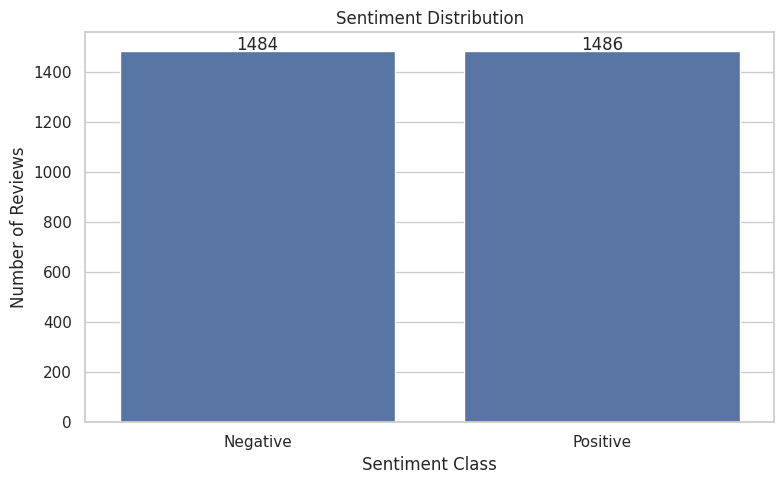

,count
sentiment,
0,1484
1,1486


In [7]:
sentiment_counts = (
    df["sentiment"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=["Negative", "Positive"],
    y=sentiment_counts.values
)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment Class")
plt.ylabel("Number of Reviews")

for index, value in enumerate(
    sentiment_counts.values
):
    ax.text(
        index,
        value + 5,
        str(value),
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "sentiment-distribution.png",
    dpi=300
)

plt.show()

display(sentiment_counts)

### 7.2 Positive and Negative Review Examples

Representative positive and negative reviews are examined to understand how sentiment is expressed in natural language.

Positive reviews may contain expressions of satisfaction, appreciation or recommendation, while negative reviews may describe dissatisfaction, disappointment or criticism.

Examining real examples helps identify the challenges of sentiment classification, including context-dependent language and mixed opinions.

In [8]:
print("POSITIVE REVIEW EXAMPLES")
print("=" * 55)

positive_reviews = df[
    df["sentiment"] == 1
]

display(
    positive_reviews[
        ["review", "clean_text"]
    ].sample(
        min(5, len(positive_reviews)),
        random_state=RANDOM_STATE
    )
)

print("\nNEGATIVE REVIEW EXAMPLES")
print("=" * 55)

negative_reviews = df[
    df["sentiment"] == 0
]

display(
    negative_reviews[
        ["review", "clean_text"]
    ].sample(
        min(5, len(negative_reviews)),
        random_state=RANDOM_STATE
    )
)

POSITIVE REVIEW EXAMPLES


,review,clean_text
2566,Great place fo take out or eat in.,great place fo take out or eat in
1753,Also the music by Mark Snow is possibly the be...,also the music by mark snow is possibly the be...
865,"It seems completely secure, both holding on to...",it seems completely secure both holding on to ...
1105,Brilliant!,brilliant
857,I received my headset in good time and was hap...,i received my headset in good time and was hap...



NEGATIVE REVIEW EXAMPLES


,review,clean_text
254,poor quality and service.,poor quality and service
876,The speaker is of low quality so as making the...,the speaker is of low quality so as making the...
2071,We'll never go again.,we ll never go again
1074,It was horrendous.,it was horrendous
2903,We won't be going back.,we will not be going back


### 7.3 Word Frequency Analysis

Word frequency analysis is used to identify commonly occurring terms in positive and negative review sentences.

Common English stopwords are excluded during this exploratory analysis to make sentiment-related vocabulary easier to identify.

However, important negation words such as "not", "no" and "never" are retained because they can influence the meaning of a sentence.

Word frequencies are calculated separately for the positive and negative classes to support a comparison of sentiment-related language patterns.

In [9]:
stop_words = set(ENGLISH_STOP_WORDS)

stop_words -= {
    "not", "no", "nor", "never"
}


def get_frequent_words(text_series, top_n=15):

    words = []

    for sentence in text_series:

        for word in sentence.split():

            if (
                word not in stop_words
                and len(word) > 1
            ):
                words.append(word)

    return Counter(words).most_common(top_n)


positive_words = get_frequent_words(
    df[df["sentiment"] == 1]["clean_text"]
)

negative_words = get_frequent_words(
    df[df["sentiment"] == 0]["clean_text"]
)

positive_word_df = pd.DataFrame(
    positive_words,
    columns=["Word", "Frequency"]
)

negative_word_df = pd.DataFrame(
    negative_words,
    columns=["Word", "Frequency"]
)

print("Frequent positive words:")
display(positive_word_df)

print("\nFrequent negative words:")
display(negative_word_df)

Frequent positive words:


,Word,Frequency
0,great,191
1,good,177
2,not,119
3,film,105
4,movie,86
5,phone,83
6,best,63
7,food,60
8,place,57
9,like,56



Frequent negative words:


,Word,Frequency
0,not,454
1,bad,100
2,movie,96
3,phone,79
4,like,68
5,just,66
6,did,65
7,food,65
8,no,61
9,time,61


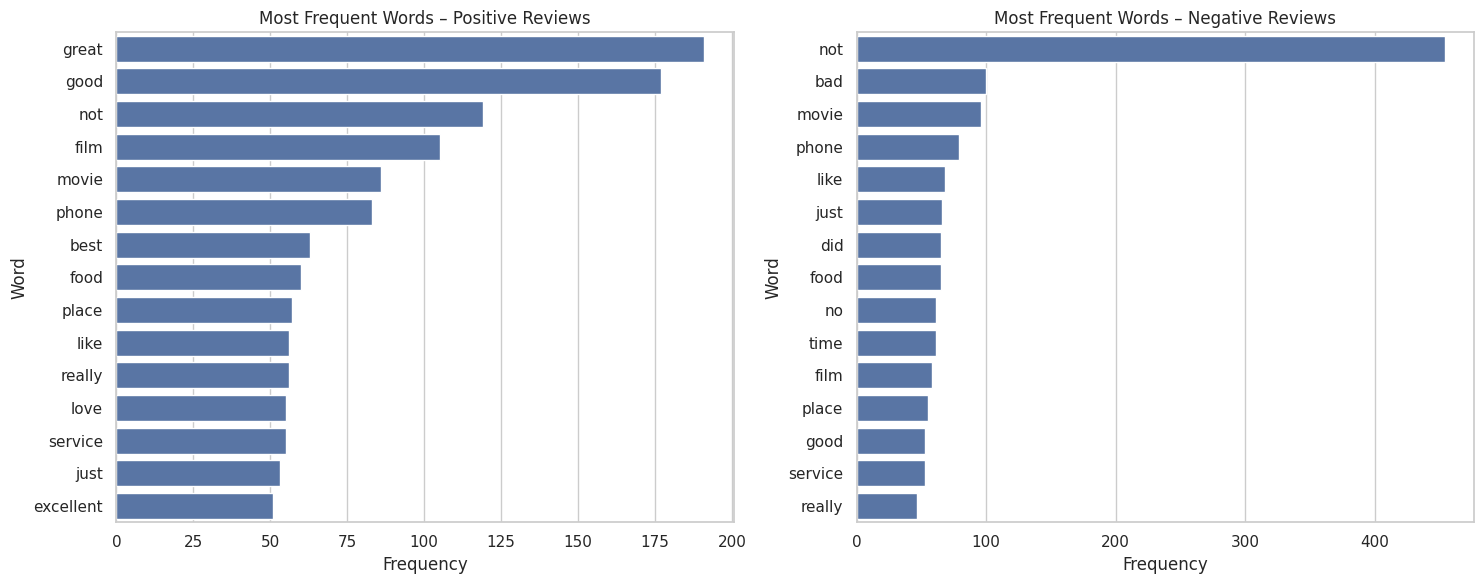

In [10]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6)
)

sns.barplot(
    data=positive_word_df,
    x="Frequency",
    y="Word",
    ax=axes[0]
)

axes[0].set_title(
    "Most Frequent Words – Positive Reviews"
)

sns.barplot(
    data=negative_word_df,
    x="Frequency",
    y="Word",
    ax=axes[1]
)

axes[1].set_title(
    "Most Frequent Words – Negative Reviews"
)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "word-frequency-comparison.png",
    dpi=300
)

plt.show()

## 8. Training and Testing Dataset Preparation

The cleaned text dataset is divided into training and testing subsets.

An 80:20 train-test split is used. The training subset is used to develop the machine learning models, while the testing subset is reserved for evaluating their performance on unseen data.

Stratified sampling is applied to maintain approximately the same distribution of positive and negative labels in both subsets.

A fixed random seed is used to make the dataset split reproducible.

In [11]:
X = df["clean_text"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = (
    train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=RANDOM_STATE,
        stratify=y
    )
)

print("Total dataset size:", len(df))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
display(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
display(y_test.value_counts().sort_index())

Total dataset size: 2970
Training samples: 2376
Testing samples: 594

Training class distribution:


,count
sentiment,
0,1187
1,1189



Testing class distribution:


,count
sentiment,
0,297
1,297


## 9. Text Feature Extraction

Traditional machine learning algorithms require numerical input. Therefore, the cleaned textual reviews must be transformed into numerical feature vectors.

### 9.1 Bag-of-Words Representation

The Bag-of-Words (BoW) approach represents a document using the frequency of words appearing in the text.

Scikit-learn's CountVectorizer is used to generate the BoW representation.

Both unigrams and bigrams are considered. Unigrams represent individual words, while bigrams represent sequences of two consecutive words.

The vectoriser is fitted on the training data only. The test data is transformed using the fitted vectoriser to prevent information leakage.

In [12]:
bow_vectorizer = CountVectorizer(
    max_features=10000,
    ngram_range=(1, 2)
)

X_train_bow = bow_vectorizer.fit_transform(
    X_train
)

X_test_bow = bow_vectorizer.transform(
    X_test
)

print(
    "BoW Training Shape:",
    X_train_bow.shape
)

print(
    "BoW Testing Shape:",
    X_test_bow.shape
)

print("\nSample vocabulary:")

print(
    bow_vectorizer.get_feature_names_out()[:30]
)

BoW Training Shape: (2376, 10000)
BoW Testing Shape: (594, 10000)

Sample vocabulary:
['10' '10 and' '10 feet' '10 for' '10 minutes' '10 on' '10 out' '10 plus'
 '10 scale' '10 series' '10 simply' '10 stars' '10 times' '10 to' '100'
 '100 times' '12' '13' '15' '15 minutes' '17' '20' '20 minutes' '2005'
 '20th' '25' '25 years' '30' '30 minutes' '35']


### 9.2 Term Frequency–Inverse Document Frequency

TF-IDF is explored as an additional text representation technique.

Unlike Bag-of-Words, which represents words using their occurrence counts, TF-IDF assigns weights based on the frequency of a word within a document and its importance across the overall document collection.

This approach reduces the relative influence of words that occur frequently across many documents.

Both BoW and TF-IDF representations are investigated to compare their effectiveness for sentiment classification.

In [13]:
tfidf_vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf_vectorizer.fit_transform(
    X_train
)

X_test_tfidf = tfidf_vectorizer.transform(
    X_test
)

print(
    "TF-IDF Training Shape:",
    X_train_tfidf.shape
)

print(
    "TF-IDF Testing Shape:",
    X_test_tfidf.shape
)

TF-IDF Training Shape: (2376, 10000)
TF-IDF Testing Shape: (594, 10000)


## 10. Machine Learning Model Training

Two traditional classification algorithms are investigated:

**Logistic Regression:** A supervised classification algorithm that estimates the probability of a class using a linear decision function.

**Linear Support Vector Machine (SVM):** A classification algorithm that learns a decision boundary to separate classes by maximising the margin between them.

Both algorithms are combined with BoW and TF-IDF representations, resulting in four experimental configurations.

Five-fold stratified cross-validation is used on the training dataset to compare the models.

The model with the highest mean cross-validation macro F1-score is selected for final evaluation.

In [14]:
models = {

    "BoW + Logistic Regression": Pipeline([
        (
            "vectorizer",
            CountVectorizer(
                max_features=10000,
                ngram_range=(1, 2)
            )
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                random_state=RANDOM_STATE
            )
        )
    ]),

    "BoW + Linear SVM": Pipeline([
        (
            "vectorizer",
            CountVectorizer(
                max_features=10000,
                ngram_range=(1, 2)
            )
        ),
        (
            "classifier",
            LinearSVC(
                random_state=RANDOM_STATE
            )
        )
    ]),

    "TF-IDF + Logistic Regression": Pipeline([
        (
            "vectorizer",
            TfidfVectorizer(
                max_features=10000,
                ngram_range=(1, 2)
            )
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                random_state=RANDOM_STATE
            )
        )
    ]),

    "TF-IDF + Linear SVM": Pipeline([
        (
            "vectorizer",
            TfidfVectorizer(
                max_features=10000,
                ngram_range=(1, 2)
            )
        ),
        (
            "classifier",
            LinearSVC(
                random_state=RANDOM_STATE
            )
        )
    ])
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1_macro"
    )

    cv_results.append({
        "Model": name,
        "CV Mean F1": scores.mean(),
        "CV F1 Std": scores.std()
    })

cv_df = pd.DataFrame(cv_results)

cv_df = cv_df.sort_values(
    "CV Mean F1",
    ascending=False
).reset_index(drop=True)

display(cv_df.round(4))

best_model_name = cv_df.iloc[0]["Model"]

print("Selected model:", best_model_name)

,Model,CV Mean F1,CV F1 Std
0,TF-IDF + Linear SVM,0.8169,0.0168
1,BoW + Logistic Regression,0.8080,0.0114
2,BoW + Linear SVM,0.8051,0.0144
3,TF-IDF + Logistic Regression,0.7995,0.0098


Selected model: TF-IDF + Linear SVM


## 11. Model Performance Evaluation

The trained classification models are evaluated using the testing dataset.

The evaluation uses four standard classification metrics:

**Accuracy:** The proportion of predictions classified correctly.

**Precision:** The proportion of predicted positive instances that are actually positive.

**Recall:** The proportion of actual positive instances correctly identified.

**F1-score:** The harmonic mean of precision and recall.

Macro-averaged precision, recall and F1-score are used when comparing overall model performance because they give equal importance to each sentiment class.

The experimental comparison helps evaluate how feature representation and classifier selection influence predictive performance.

In [15]:
evaluation_results = []
trained_models = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    evaluation_results.append({
        "Model": name,

        "Accuracy": accuracy_score(
            y_test, predictions
        ),

        "Precision": precision_score(
            y_test, predictions,
            average="macro",
            zero_division=0
        ),

        "Recall": recall_score(
            y_test, predictions,
            average="macro",
            zero_division=0
        ),

        "F1 Score": f1_score(
            y_test, predictions,
            average="macro",
            zero_division=0
        )
    })

    trained_models[name] = model

results_df = pd.DataFrame(
    evaluation_results
)

results_df = results_df.merge(
    cv_df,
    on="Model"
)

results_df = results_df.sort_values(
    "CV Mean F1",
    ascending=False
)

display(results_df.round(4))

results_df.to_csv(
    RESULTS_DIR / "model-comparison.csv",
    index=False
)

,Model,Accuracy,Precision,Recall,F1 Score,CV Mean F1,CV F1 Std
3,TF-IDF + Linear SVM,0.8502,0.8508,0.8502,0.8501,0.8169,0.0168
0,BoW + Logistic Regression,0.8384,0.8384,0.8384,0.8384,0.8080,0.0114
1,BoW + Linear SVM,0.8283,0.8283,0.8283,0.8283,0.8051,0.0144
2,TF-IDF + Logistic Regression,0.8316,0.8317,0.8316,0.8316,0.7995,0.0098


### 11.1 Model Comparison Visualisation

A bar chart is created to compare the test accuracy of the four model configurations.

Visual comparison makes it easier to identify performance differences between the classification algorithms and text representations.

The chart is saved as supporting evidence for the practical portfolio.

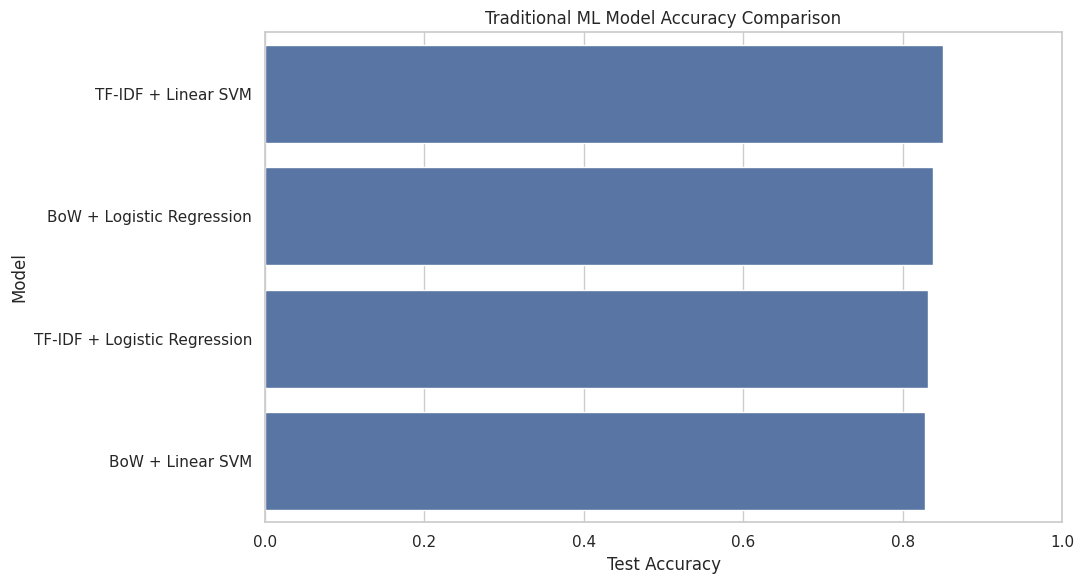

In [16]:
plot_df = results_df.sort_values(
    "Accuracy",
    ascending=False
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=plot_df,
    x="Accuracy",
    y="Model"
)

plt.title(
    "Traditional ML Model Accuracy Comparison"
)

plt.xlabel("Test Accuracy")
plt.ylabel("Model")

plt.xlim(0, 1)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "model-comparison.png",
    dpi=300
)

plt.show()

### 11.2 Selected Model Evaluation

The model selected using the highest mean cross-validation macro F1-score is evaluated on the held-out testing data.

Its accuracy, precision, recall and F1-score are calculated, followed by a detailed classification report showing performance for both negative and positive sentiment classes.

This evaluation measures the ability of the selected model to generalise to previously unseen review sentences.

In [17]:
best_model = trained_models[best_model_name]

best_predictions = best_model.predict(
    X_test
)

accuracy = accuracy_score(
    y_test, best_predictions
)

precision = precision_score(
    y_test,
    best_predictions,
    average="macro"
)

recall = recall_score(
    y_test,
    best_predictions,
    average="macro"
)

f1 = f1_score(
    y_test,
    best_predictions,
    average="macro"
)

print("FINAL MODEL EVALUATION")
print("=" * 55)

print("Model:", best_model_name)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nClassification report:")

report = classification_report(
    y_test,
    best_predictions,
    target_names=["Negative", "Positive"]
)

print(report)

(RESULTS_DIR / "classification-report.txt").write_text(
    report,
    encoding="utf-8"
)

FINAL MODEL EVALUATION
Model: TF-IDF + Linear SVM
Accuracy : 0.8502
Precision: 0.8508
Recall   : 0.8502
F1-score : 0.8501

Classification report:
              precision    recall  f1-score   support

    Negative       0.87      0.83      0.85       297
    Positive       0.84      0.87      0.85       297

    accuracy                           0.85       594
   macro avg       0.85      0.85      0.85       594
weighted avg       0.85      0.85      0.85       594



326

### 11.3 Confusion Matrix Analysis

A confusion matrix is generated to examine the selected model's classification results in detail.

The matrix shows the number of correctly and incorrectly predicted negative and positive reviews.

It helps identify false-positive and false-negative predictions and provides additional insight into how the model performs across sentiment classes.

The confusion matrix complements the accuracy, precision, recall and F1-score measurements.

Confusion Matrix:
[[246  51]
 [ 38 259]]


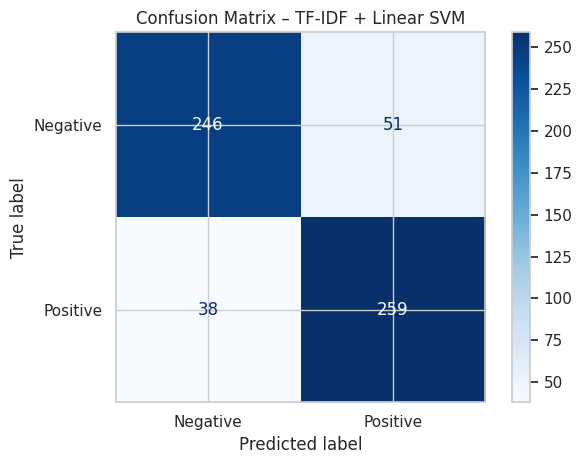

In [18]:
cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=[0, 1]
)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "Confusion Matrix – " + best_model_name
)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "confusion-matrix.png",
    dpi=300
)

plt.show()

### 11.4 Classification Error Analysis

The incorrectly classified reviews are examined to investigate limitations of the selected model.

Error analysis provides useful evidence about the challenges of traditional machine learning approaches to sentiment analysis.

Potential difficulties include ambiguous wording, mixed opinions, domain-specific expressions, sarcasm and insufficient contextual understanding.

The actual misclassified examples are inspected to determine whether any of these factors may have contributed to the prediction errors.

In [19]:
error_analysis = df.loc[
    X_test.index,
    ["review", "clean_text"]
].copy()

error_analysis["Actual"] = y_test.values
error_analysis["Predicted"] = best_predictions

misclassified = error_analysis[
    error_analysis["Actual"] !=
    error_analysis["Predicted"]
]

print(
    "Number of misclassified reviews:",
    len(misclassified)
)

display(misclassified.head(15))

misclassified.to_csv(
    RESULTS_DIR / "misclassified-reviews.csv",
    index=False
)

Number of misclassified reviews: 89


,review,clean_text,Actual,Predicted
660,Much less than the jawbone I was going to repl...,much less than the jawbone i was going to repl...,1,0
1769,This film highlights the fundamental flaws of ...,this film highlights the fundamental flaws of ...,1,0
2212,"The descriptions said ""yum yum sauce"" and anot...",the descriptions said yum yum sauce and anothe...,0,1
199,The color is even prettier than I thought it w...,the color is even prettier than i thought it w...,1,0
2231,We had 7 at our table and the service was pret...,we had 7 at our table and the service was pret...,1,0
1392,Not too screamy not to masculine but just righ...,not too screamy not to masculine but just right,1,0
1233,The soundtrack sucked.,the soundtrack sucked,0,1
2812,"for 40 bucks a head, i really expect better food.",for 40 bucks a head i really expect better food,0,1
567,"I've had no trouble accessing the Internet, do...",i ve had no trouble accessing the internet dow...,1,0
1577,Every element of this story was so over the to...,every element of this story was so over the to...,0,1


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## 12. Testing with New Sentences

The trained sentiment classification model is tested using new sentences that were not part of the original dataset.

A custom prediction function is developed to accept a review sentence, preprocess the text and generate a sentiment prediction.

The function applies the same preprocessing operations used during model training.

Both positive and negative examples are tested, together with sentences containing negation or mixed sentiment.

This demonstrates the practical application of the trained model to unseen textual information.

In [20]:
def predict_sentiment(sentence):

    cleaned = preprocess_text(sentence)

    prediction = best_model.predict(
        [cleaned]
    )[0]

    sentiment = (
        "Positive"
        if prediction == 1
        else "Negative"
    )

    return {
        "Original Sentence": sentence,
        "Cleaned Sentence": cleaned,
        "Predicted Sentiment": sentiment
    }


new_sentences = [
    "This product is absolutely amazing!",
    "The movie was terrible and boring.",
    "I really enjoyed the experience.",
    "The food was not good at all.",
    "The service was excellent.",
    "I would never recommend this product.",
    "The quality is acceptable but not impressive.",
    "I love this place!"
]

prediction_results = pd.DataFrame([
    predict_sentiment(sentence)
    for sentence in new_sentences
])

display(prediction_results)

prediction_results.to_csv(
    RESULTS_DIR / "new-sentence-predictions.csv",
    index=False
)

,Original Sentence,Cleaned Sentence,Predicted Sentiment
0,This product is absolutely amazing!,this product is absolutely amazing,Positive
1,The movie was terrible and boring.,the movie was terrible and boring,Negative
2,I really enjoyed the experience.,i really enjoyed the experience,Positive
3,The food was not good at all.,the food was not good at all,Negative
4,The service was excellent.,the service was excellent,Positive
5,I would never recommend this product.,i would never recommend this product,Positive
6,The quality is acceptable but not impressive.,the quality is acceptable but not impressive,Negative
7,I love this place!,i love this place,Positive


## 13. Saving and Reloading the Trained Model

The selected classification model is saved using Joblib.

Saving the model allows it to be reused without repeating the entire training process.

The model is reloaded and tested with a sample sentence to verify that the saved classifier remains functional.

This step demonstrates model persistence and improves the reproducibility of the practical implementation.

In [21]:
model_path = OUTPUT_DIR / "sentiment-model.joblib"

joblib.dump(
    best_model,
    model_path
)

print("Model saved successfully.")
print("Saved location:", model_path)

loaded_model = joblib.load(model_path)

test_sentence = preprocess_text(
    "The product is excellent!"
)

prediction = loaded_model.predict(
    [test_sentence]
)[0]

print(
    "Reloaded model prediction:",
    "Positive" if prediction == 1 else "Negative"
)

Model saved successfully.
Saved location: /content/Lab-01-Machine-Learning/output/sentiment-model.joblib
Reloaded model prediction: Positive


## 14. Experiment Summary

The main experimental settings and evaluation results are saved in a structured JSON file.

The summary records the dataset size, training and testing sample counts, selected classification model, random seed and final performance metrics.

Saving these details helps maintain consistency between the notebook, experimental outputs and portfolio documentation.

In [22]:
experiment_summary = {
    "Laboratory": "Lab 01",
    "Dataset": "UCI Sentiment Labelled Sentences",
    "Original Records": original_count,
    "Cleaned Records": len(df),
    "Training Records": len(X_train),
    "Testing Records": len(X_test),
    "Selected Model": best_model_name,
    "Random Seed": RANDOM_STATE,
    "Accuracy": float(accuracy),
    "Precision": float(precision),
    "Recall": float(recall),
    "F1 Score": float(f1)
}

summary_file = (
    RESULTS_DIR / "experiment-summary.json"
)

with open(
    summary_file,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        experiment_summary,
        file,
        indent=4
    )

print(json.dumps(
    experiment_summary,
    indent=4
))

{
    "Laboratory": "Lab 01",
    "Dataset": "UCI Sentiment Labelled Sentences",
    "Original Records": 3000,
    "Cleaned Records": 2970,
    "Training Records": 2376,
    "Testing Records": 594,
    "Selected Model": "TF-IDF + Linear SVM",
    "Random Seed": 42,
    "Accuracy": 0.8501683501683501,
    "Precision": 0.8508405270331667,
    "Recall": 0.8501683501683501,
    "F1 Score": 0.8500965500032609
}
